# Default prediction on Lending Club loans

Can we predict whether a loan defaults using only what is known when it is issued?
Two models are compared: a logistic regression baseline and LightGBM.

**Setup**
- Data comes from the DuckDB warehouse (`fact_loans` joined to its dimensions).
- Only resolved loans are used: `is_default` is TRUE (charged off / default) or FALSE (fully paid).
  Loans still in progress have no outcome yet and are excluded.
- Features are application-time only: loan amount, interest rate, term, grade, DTI, annual income,
  employment length, purpose and state.
  `total_pymnt`, `total_rec_*` and `recoveries` are payments made *after* issue, so they leak the outcome and are left out.
- Time-based split: train on loans issued 2007-2015, test on 2016-2017. No hyperparameter tuning, so there is no validation set.

Run from the project root: `uv run --group modeling jupyter nbconvert --execute --to notebook --inplace notebooks/default_model.ipynb`

In [1]:
import json
from pathlib import Path

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TRAIN_END_YEAR = 2015
TEST_YEARS = (2016, 2017)

/Users/dhwanil/Desktop/ONGOING PROJECTS/FINISHED PROJECTS/Financial Data Warehouse Pipeline/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load resolved loans from the warehouse

In [2]:
QUERY = """
    SELECT f.is_default::INT AS defaulted,
           t.year            AS issue_year,
           f.loan_amnt, f.int_rate, f.dti, f.annual_inc,
           f.funded_amnt, f.total_pymnt,
           p.term, p.purpose,
           g.grade,
           b.emp_length, b.addr_state
    FROM fact_loans AS f
    INNER JOIN dim_time       AS t ON f.time_id = t.time_id
    INNER JOIN dim_purpose    AS p ON f.purpose_id = p.purpose_id
    INNER JOIN dim_loan_grade AS g ON f.grade_id = g.grade_id
    INNER JOIN dim_borrower   AS b ON f.borrower_id = b.borrower_id
    WHERE f.is_default IS NOT NULL
"""
con = duckdb.connect(str(ROOT / "warehouse.duckdb"), read_only=True)
loans = con.execute(QUERY).df()
con.close()

# '36 months' -> 36;  '10+ years' -> 10;  '< 1 year' -> 0;  missing stays NaN
loans["term_months"] = loans["term"].str.extract(r"(\d+)", expand=False).astype(float)
loans["emp_years"] = (
    loans["emp_length"].str.replace("< 1", "0", regex=False).str.extract(r"(\d+)", expand=False).astype(float)
)
loans = loans.drop(columns=["term", "emp_length"])

print(f"{len(loans):,} resolved loans, default rate {loans['defaulted'].mean():.2%}")
loans.isna().mean().loc[lambda s: s > 0].rename("null share")

1,348,099 resolved loans, default rate 19.98%


dti           0.000277
annual_inc    0.000003
emp_years     0.058267
Name: null share, dtype: float64

## 2. Time-based split

A random split would let the model learn from loans issued after the ones it is tested on.
Splitting by issue year mimics real use: train on the past, score the future.

In [3]:
NUMERIC = ["loan_amnt", "int_rate", "dti", "annual_inc", "term_months", "emp_years"]
CATEGORICAL = ["grade", "purpose", "addr_state"]
FEATURES = NUMERIC + CATEGORICAL

train = loans[loans["issue_year"] <= TRAIN_END_YEAR]
test = loans[loans["issue_year"].isin(TEST_YEARS)]
X_train, y_train = train[FEATURES], train["defaulted"]
X_test, y_test = test[FEATURES], test["defaulted"]

print(f"train: {len(train):,} loans, default rate {y_train.mean():.2%}")
print(f"test:  {len(test):,} loans, default rate {y_test.mean():.2%}")
test.groupby("issue_year")["defaulted"].agg(["size", "mean"]).rename(columns={"size": "loans", "mean": "default rate"})

train: 829,355 loans, default rate 18.46%
test:  462,426 loans, default rate 23.23%


,loans,default rate
issue_year,,
2016,293105,0.232859
2017,169321,0.231330


**Caveat on the test set.** The data ends in 2018. A 2017 loan only appears here if it already finished
(paid off or defaulted) by then, and defaults tend to resolve before full repayment.
The 2017 default rate is therefore inflated relative to what those loans will eventually show.
Rankings (AUC, KS) are less affected than absolute rates (calibration).

## 3. Models

In [4]:
logit = make_pipeline(
    ColumnTransformer(
        [
            ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
        ]
    ),
    LogisticRegression(max_iter=500),
)
logit.fit(X_train, y_train)
logit_scores = logit.predict_proba(X_test)[:, 1]

In [5]:
# LightGBM handles missing values and categoricals natively; test categories must match train.
category_types = {col: pd.CategoricalDtype(sorted(X_train[col].unique())) for col in CATEGORICAL}


def for_lgbm(frame: pd.DataFrame) -> pd.DataFrame:
    return frame.astype(category_types)


GBM_PARAMS = dict(
    n_estimators=300, learning_rate=0.05, num_leaves=63, min_child_samples=200,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=0, verbose=-1,
)
gbm = lgb.LGBMClassifier(**GBM_PARAMS)
gbm.fit(for_lgbm(X_train), y_train)
gbm_scores = gbm.predict_proba(for_lgbm(X_test))[:, 1]

## 4. Results

In [6]:
def ks_statistic(y_true, scores) -> float:
    fpr, tpr, _ = roc_curve(y_true, scores)
    return float(np.max(tpr - fpr))


candidates = {
    "Interest rate only": test["int_rate"].to_numpy(),
    "Logistic regression": logit_scores,
    "LightGBM": gbm_scores,
}
metrics = pd.DataFrame(
    {
        name: {
            "AUC": roc_auc_score(y_test, scores),
            "KS": ks_statistic(y_test, scores),
            "Brier": brier_score_loss(y_test, scores) if name != "Interest rate only" else np.nan,
        }
        for name, scores in candidates.items()
    }
).T
metrics.round(4)

,AUC,KS,Brier
Interest rate only,0.6870,0.2724,NaN
Logistic regression,0.6936,0.2821,0.1663
LightGBM,0.6999,0.2879,0.1658


The interest-rate-only row is a sanity floor: Lending Club already prices risk into the rate and grade,
so a model has to beat that to add anything. Brier score only makes sense for probabilities, so it is blank for the rate.

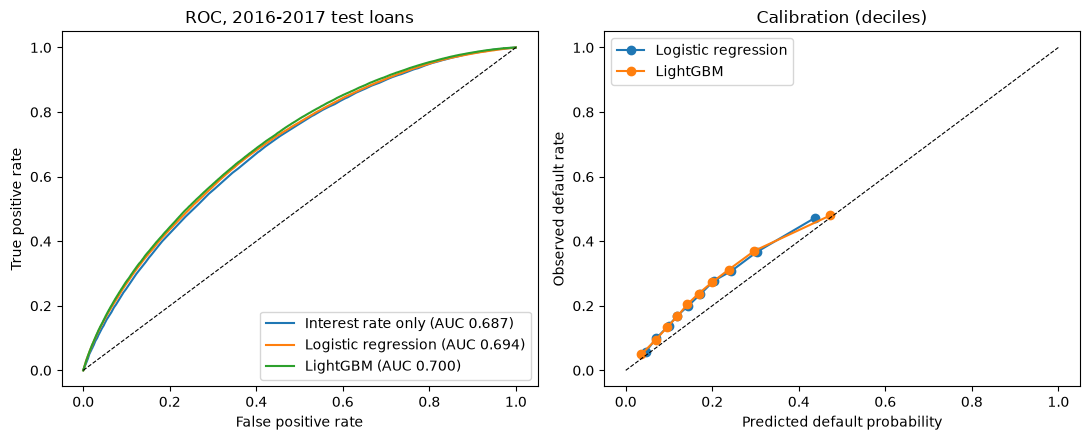

In [7]:
fig, (ax_roc, ax_cal) = plt.subplots(1, 2, figsize=(11, 4.5))

for name, scores in candidates.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    ax_roc.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, scores):.3f})")
ax_roc.plot([0, 1], [0, 1], "k--", linewidth=0.8)
ax_roc.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC, 2016-2017 test loans")
ax_roc.legend(loc="lower right")

for name, scores in [("Logistic regression", logit_scores), ("LightGBM", gbm_scores)]:
    observed, predicted = calibration_curve(y_test, scores, n_bins=10, strategy="quantile")
    ax_cal.plot(predicted, observed, marker="o", label=name)
ax_cal.plot([0, 1], [0, 1], "k--", linewidth=0.8)
ax_cal.set(xlabel="Predicted default probability", ylabel="Observed default rate", title="Calibration (deciles)")
ax_cal.legend()

plt.tight_layout()
plt.show()

## 5. What drives the LightGBM score

SHAP values on a random sample of 5,000 test loans. Larger bars mean the feature moves predictions more on average.

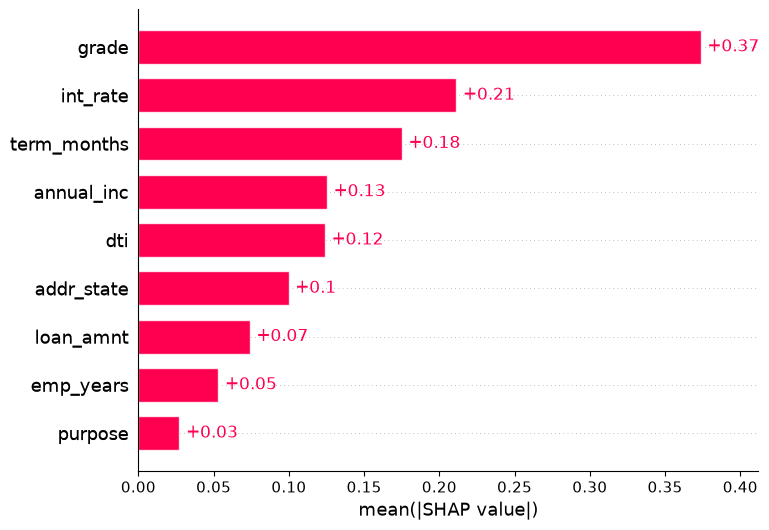

In [8]:
sample = for_lgbm(X_test).sample(5000, random_state=0)
explanation = shap.TreeExplainer(gbm)(sample)
if explanation.values.ndim == 3:  # some SHAP versions return one slice per class
    explanation = explanation[:, :, 1]
shap.plots.bar(explanation, max_display=len(FEATURES))

## 6. Approval cutoff vs profit

Which loans should be approved? Rank applicants by predicted default risk, approve the safest share,
and see what the lender would actually have earned.

- **Profit per loan** is `total_pymnt - funded_amnt`: everything the borrower paid back (interest, fees and recoveries on
  defaults) minus the money lent. It ignores funding cost, servicing cost and the time value of money, so read it as a
  relative measure.
- **Cohort: 36-month loans issued in 2015.** They had all run their full term by the end of the data (late 2018), so every
  outcome is final. Recent loans cannot be used for profit: the 2016-2017 test set above only contains loans that already
  resolved, and its realised profit is biased downward (overall return is negative).
- A fresh LightGBM is trained only on loans issued before 2015, so the cohort is scored out of sample.

In [9]:
PROFIT_YEAR = 2015
history = loans[loans["issue_year"] < PROFIT_YEAR]
cohort = loans[(loans["issue_year"] == PROFIT_YEAR) & (loans["term_months"] == 36)].copy()

profit_gbm = lgb.LGBMClassifier(**GBM_PARAMS).fit(for_lgbm(history[FEATURES]), history["defaulted"])
cohort["model_risk"] = profit_gbm.predict_proba(for_lgbm(cohort[FEATURES]))[:, 1]
cohort["profit"] = cohort["total_pymnt"] - cohort["funded_amnt"]

print(f"cohort: {len(cohort):,} loans, default rate {cohort['defaulted'].mean():.2%}")
print(f"model AUC on cohort: {roc_auc_score(cohort['defaulted'], cohort['model_risk']):.3f}")
print(f"approve everyone: profit ${cohort['profit'].sum() / 1e6:,.1f}M, return {cohort['profit'].sum() / cohort['funded_amnt'].sum():.2%}")

cohort: 283,026 loans, default rate 14.89%
model AUC on cohort: 0.682
approve everyone: profit $237.4M, return 6.55%


In [10]:
def approval_sweep(frame: pd.DataFrame, risk_column: str) -> pd.DataFrame:
    """Approve the lowest-risk share of loans, for shares from 5% to 100%."""
    ranked = frame.sort_values(risk_column).reset_index(drop=True)
    rows = []
    for share in np.arange(0.05, 1.0001, 0.05):
        approved = ranked.head(round(len(ranked) * share))
        rows.append(
            {
                "approve_share": round(share, 2),
                "loans": len(approved),
                "default_rate": approved["defaulted"].mean(),
                "profit_musd": approved["profit"].sum() / 1e6,
                "return_on_funded": approved["profit"].sum() / approved["funded_amnt"].sum(),
                "max_risk_approved": approved["model_risk"].max(),
            }
        )
    return pd.DataFrame(rows).set_index("approve_share")


by_model = approval_sweep(cohort, "model_risk")
by_rate = approval_sweep(cohort, "int_rate")
best_share = by_model["profit_musd"].idxmax()
print(f"Total profit peaks when approving the safest {best_share:.0%}")

SHARES = [0.2, 0.4, 0.6, 0.8, 1.0]
comparison = pd.DataFrame(
    {
        "default_rate": by_model.loc[SHARES, "default_rate"],
        "model_profit_musd": by_model.loc[SHARES, "profit_musd"],
        "model_return": by_model.loc[SHARES, "return_on_funded"],
        "rate_profit_musd": by_rate.loc[SHARES, "profit_musd"],
        "rate_return": by_rate.loc[SHARES, "return_on_funded"],
    }
)
comparison.round(3)

Total profit peaks when approving the safest 100%


,default_rate,model_profit_musd,model_return,rate_profit_musd,rate_return
approve_share,,,,,
0.2,0.048,62.640,0.071,55.611,0.068
0.4,0.072,118.980,0.073,109.413,0.070
0.6,0.093,169.634,0.074,161.399,0.072
0.8,0.117,211.378,0.072,206.054,0.070
1.0,0.149,237.433,0.066,237.433,0.066


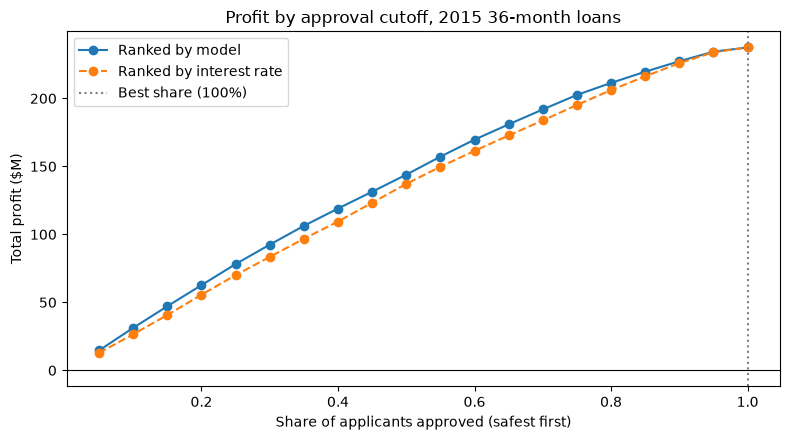

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(by_model.index, by_model["profit_musd"], marker="o", label="Ranked by model")
ax.plot(by_rate.index, by_rate["profit_musd"], marker="o", linestyle="--", label="Ranked by interest rate")
ax.axhline(0, color="k", linewidth=0.8)
ax.axvline(best_share, color="grey", linestyle=":", label=f"Best share ({best_share:.0%})")
ax.set(xlabel="Share of applicants approved (safest first)", ylabel="Total profit ($M)", title="Profit by approval cutoff, 2015 36-month loans")
ax.legend()
plt.tight_layout()
plt.show()

Each slice below is a fifth of the cohort, from lowest to highest predicted risk. This shows where the money is made and lost.

In [12]:
cohort["risk_quintile"] = pd.qcut(cohort["model_risk"], 5, labels=["1 (safest)", "2", "3", "4", "5 (riskiest)"])
by_quintile = cohort.groupby("risk_quintile", observed=True).agg(
    loans=("profit", "size"),
    default_rate=("defaulted", "mean"),
    profit_musd=("profit", lambda s: s.sum() / 1e6),
    funded_musd=("funded_amnt", lambda s: s.sum() / 1e6),
)
by_quintile["return_on_funded"] = by_quintile["profit_musd"] / by_quintile["funded_musd"]
by_quintile.drop(columns="funded_musd").round(3)

,loans,default_rate,profit_musd,return_on_funded
risk_quintile,,,,
1 (safest),56606,0.048,62.631,0.071
2,56605,0.096,56.350,0.076
3,56605,0.135,50.653,0.075
4,56605,0.191,41.744,0.064
5 (riskiest),56605,0.275,26.055,0.039


And the same view by Lending Club grade:

In [13]:
by_grade = cohort.groupby("grade").agg(
    loans=("profit", "size"),
    default_rate=("defaulted", "mean"),
    profit_musd=("profit", lambda s: s.sum() / 1e6),
    funded_musd=("funded_amnt", lambda s: s.sum() / 1e6),
)
by_grade["return_on_funded"] = by_grade["profit_musd"] / by_grade["funded_musd"]
by_grade.drop(columns="funded_musd").round(3)

,loans,default_rate,profit_musd,return_on_funded
grade,,,,
A,70118,0.054,69.901,0.069
B,91725,0.119,85.311,0.074
C,77423,0.194,60.237,0.065
D,32711,0.262,19.744,0.049
E,9443,0.328,2.624,0.022
F,1361,0.424,-0.257,-0.018
G,245,0.461,-0.127,-0.053


In [14]:
out = {
    "train_years": f"2007-{TRAIN_END_YEAR}",
    "test_years": f"{TEST_YEARS[0]}-{TEST_YEARS[1]}",
    "train_loans": int(len(train)),
    "test_loans": int(len(test)),
    "test_default_rate": round(float(y_test.mean()), 4),
    "models": metrics.round(4).astype(object).where(metrics.notna(), None).to_dict(orient="index"),
    "profit_cohort": {
        "description": "36-month loans issued in 2015, scored by a model trained on loans issued before 2015",
        "loans": int(len(cohort)),
        "approve_all": {
            "profit_musd": round(float(cohort["profit"].sum() / 1e6), 1),
            "return_on_funded": round(float(cohort["profit"].sum() / cohort["funded_amnt"].sum()), 4),
        },
        "profit_peaks_at_approve_share": float(best_share),
        "by_approve_share": comparison.round(4).to_dict(orient="index"),
        "by_risk_quintile": by_quintile[["default_rate", "profit_musd", "return_on_funded"]].round(4).to_dict(orient="index"),
        "by_grade": by_grade[["default_rate", "profit_musd", "return_on_funded"]].round(4).to_dict(orient="index"),
    },
}
(ROOT / "notebooks" / "metrics.json").write_text(json.dumps(out, indent=2) + "\n")
out

{'train_years': '2007-2015',
 'test_years': '2016-2017',
 'train_loans': 829355,
 'test_loans': 462426,
 'test_default_rate': 0.2323,
 'models': {'Interest rate only': {'AUC': 0.687, 'KS': 0.2724, 'Brier': None},
  'Logistic regression': {'AUC': 0.6936, 'KS': 0.2821, 'Brier': 0.1663},
  'LightGBM': {'AUC': 0.6999, 'KS': 0.2879, 'Brier': 0.1658}},
 'profit_cohort': {'description': '36-month loans issued in 2015, scored by a model trained on loans issued before 2015',
  'loans': 283026,
  'approve_all': {'profit_musd': 237.4, 'return_on_funded': 0.0655},
  'profit_peaks_at_approve_share': 1.0,
  'by_approve_share': {0.2: {'default_rate': 0.0475,
    'model_profit_musd': 62.6398,
    'model_return': 0.0713,
    'rate_profit_musd': 55.6112,
    'rate_return': 0.0679},
   0.4: {'default_rate': 0.0718,
    'model_profit_musd': 118.9797,
    'model_return': 0.0732,
    'rate_profit_musd': 109.4125,
    'rate_return': 0.0698},
   0.6: {'default_rate': 0.0928,
    'model_profit_musd': 169.6342,